단층 퍼셉트론<br>
    - 단층 퍼셉트론의 한계<br>
다층 퍼셉트론<br>
딥러닝 모델의 학습 방법<br>
    - 순전파와 역전파, 연쇄 법칙<br>
    - 손실 함수의 정의와 종류<br>
    - 활성화 함수의 정의와 종류<br>
    - 옵티마이저의 정의와 종류

# 1. 인공신경망이란?
- 개념: 우리 뇌의 신경망(뇌를 구성하는 신경 세포끼리 서로 연결되어 정보를 처리하는 구조)을 모방한 모델
- **퍼셉트론** : 초기 형태의 인공신경망으로, 딥러닝의 기원이 되는 선형 이진 분류기
- 퍼셉트론의 출력값을 구하는 절차
    1. 입력값과 가중치의 곱을 구함
    2. 곱한 값들의 총합을 구함
    3. 총합이 임계값을 넘으면 1, 넘지 않으면 0으로 출력

- 용어 정리
    - 가중치: 입력값이 출력값에 주는 영향력(중요도)을 결정. 가중치가 클수록 해당 입력값이 중요함을 의미
    - 활성화 함수: 입력값(가중치와 입력값의 곱의 합+편향)을 최종적으로 어떤 출력 신호로 변환하여 다음 층으로 보낼지 결정하는 계산식
    - 임계값: 계단 함수에서는 가중합이 임계값을 넘으면 1, 넘지 못하면 0을 출력
    - 편향: 임계값과 편향은 표현의 차이 (계단함수 구현 식에서 임계값을 좌변으로 넘기면 편향으로 표현 가능)

# 2. 단층 퍼셉트론과 그 한계

- **단층 퍼셉트론이란?** : 단순히 입력층과 출력층으로만 이루어진 퍼셉트론
- 논리게이트 : 디지털 회로에서 기본적인 연산에 사용되는 구성요소로 AND, OR, NAND, NOR, XOR 등 다양한 종류가 존재. 이러한 논리 게이트를 조합하여 복잡한 논리 회로를 구성할 수 있음.<br>
    -> **단층 퍼셉트론을 이용하면 AND, NAND, OR 논리 게이트를 쉽게 구현할 수 있음!**

- 논리 게이트 예시<br>

| 게이트      | 조건          | 가중치·편향 예시 [w1, w2, b] |
| -------- | ----------- | --------------------- |
| **AND**  | 둘 다 1일 때만 1 | [0.5, 0.5, -0.7]      |
| **OR**   | 둘 다 0일 때만 0 | [0.6, 0.6, -0.5]      |
| **NAND** | 둘 다 1일 때만 0 | [-0.5, -0.5, 0.7]     |
| **XOR**  | 서로 다를 때만 1  | **가능한 조합이 없음** |

#### **단층 퍼셉트론의 한계 -> XOR 게이트를 구현할 수 없다!!**
- 퍼셉트론은 입력값과 가중치의 **선형 결합**으로 이루어진 구조이기 때문에, **단층 퍼셉트론은 직선 하나로 두 영역을 나눌 수 있는 선형 분류 문제**에 대해서만 구현할 수 있음
- **XOR 게이트는 직선이 아닌 비선형/곡선 영역으로 분리해야만 구현할 수 있다**<br>
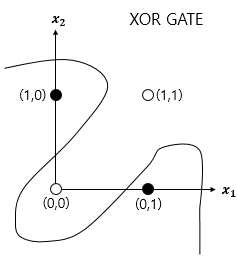

- 퍼셉트론의 층을 더 쌓아서 XOR 게이트 문제 해결 가능!! 


# 3. 다층퍼셉트론

- 등장배경: 단층 퍼셉트론의 한계(XOR 게이트 같은 비선형 문제 해결 불가)를 극복하기 위해 등장
- **은닉층에서 비선형 활성화 함수를 적용해 새로운 특징**을 만들고, **다음 층에서 그 특징들을 조합**하여 비선형 문제 해결!

# 4. 딥러닝 모델의 학습 방법

## 4.1 순전파와 역전파
1. 순전파를 통해 입력값으로부터 예측 수행
2. 오차 계산을 통해 예측 정확도 측정
3. 역전파를 통해 출력층에서 다시 입력층 방향으로 오차 전달
4. 가중치 업데이트
5. 1~4를 반복…

-> 이 과정을 반복하면서 오차값을 0에 가깝게 만듦

- 이러한 순전파/역전파 과정은 **연쇄법칙**을 통해 일어난다

##### 연쇄법칙
- 개념: 합성함수의 미분은 각 함수의 미분의 곱으로 나타낼 수 있다는 법칙
- 사용하는 이유 : 딥러닝에서는 입력값이 여러 은닉층을 거친 후 최종 출력값으로 나옴. 따라서 입력값이 최종 출력에 미친 영향을 파악하기 위해서는 **각 층이 다음 층에 미친 영향을 순서대로 곱해나가야함.**

- 오차를 줄이기 위해 역전파 과정에서 **각 가중치가 최종 손실에 얼마나 기여했는지 계산**해야 하는데, 이때 **연쇄법칙**을 사용!
- 계산식: $$\frac{dC}{dA} = \frac{dC}{dB} \times \frac{dB}{dA}$$
- C가 A에게 준 영향을 계산하기 위해 단계적으로 C가 B에 미친 영향을 먼저 구하고, B가 A에 미친 영향을 구한 뒤, 결과적으로 C가 A에게 준 영향을 구함

##### 기울기 소실 문제
- **은닉층이 깊은 신경망**에서 역전파 시 **각 층의 미분값이 1보다 작으면**, 이 값들이 **연쇄적으로 곱해지면서 입력층에 가까운 층일수록 기울기가 0에 수렴**하는 현상. 그 결과 **앞쪽 층의 가중치가 거의 업데이트되지 않아 학습이 제대로 이루어지지 않는다.**

## 4.2 손실 함수
- 개념: **실제값(정답)과 예측값(출력값)의 차이**를 계산하는 데 사용되는 함수
- 일반적으로 회귀에서는 평균제곱오차(MSE)를, 분류에서는 크로스 엔트로피 오차를 사용

##### 손실함수의 종류
1. 평균제곱오차(MSE)
    - **예측값이 연속적**이고, 실제값과 예측값의 차이를 직접 측정하는 **회귀문제**에 적합
2. 이진 크로스 엔트로피(BCE)
    - 이진분류문제(로지스틱 회귀)에서 사용하는 손실함수
    - BCE는 실제 정답에 부여한 확률에 −log를 적용한 손실로, 정답을 잘 맞출수록 손실 함수값은 작아지고 못 맞출수록 손실 함수 값은 커짐. 
    - 예시)

    -   | 정답에 준 확률 q | −log(q) | 해석 |
        |---|---|---|
        | 1.0 | 0 | 완벽 → 벌점 없음 |
        | 0.9 | 0.11 | 잘 맞힘 → 벌점 작음 |
        | 0.5 | 0.69 | 반반 찍음 |
        | 0.1 | 2.30 | 틀림 → 벌점 큼 |
        | 0.01 | 4.61 | 확신하며 틀림 → 벌점 매우 큼 |
    - BCE는 **얼마나 확신을 가지고 예측했는지도 loss에 반영**

3. 크로스 엔트로피 오차(CEE)
- 다중 클래스 분류 문제에서 **예측 확률이 실제 클래스와 얼마나 일치**하는지를 평가하는데 적합함.
- 다중 클래스 분류 문제 예시) 손글씨 숫자 인식(MNIST), 이미지 분류(CIFAR-10)

## 4.3 활성화 함수
- 활성화 함수가 필요한 이유? 
1. 비선형성 필요
    - 활성화 함수가 없으면 층을 아무리 쌓아도 선형 계산의 반복임
2. 미분이 되어야 한다.
    - 연쇄법칙을 적용하기 위해서는 미분이 가능해야 하지만, 계단함수의 경우 미분이 불가능함. 

##### 활성화 함수의 종류
1. 계단함수 
    - $$h(x) = \begin{cases} 1 & (x \geq 0) \\ 0 & (x < 0) \end{cases}$$
    - 미분이 불가능하여 다층 퍼셉트론에서는 사용하지 않음
2. 시그모이드 함수 
    - $$f(x)=\frac{1}{1+e^{-x}}$$
    - 입력 신호를 0과 1 사이의 연속적인 값으로 변환하는 비선형 함수
    - 계단함수와 달리 출력값이 **연속적으로 변화**-> 맞다/틀리다가 얼마나 확실한지 표현가능하고, 미분도 가능함. 
    - 하지만 미분값이 최대 0.25로, 층을 곱해나가면 **기울기 소실**이 발생
3. ReLU (중요)
    - $$f(x)=\max(0,x)$$
    - 입력이 0보다 크면 그대로, 0 이하면 0을 출력하는 비선형 함수
    - 장점
        1. 계산이 간단하고 효율적
        2. 비선형성 해결
        3. 기울기 소실 문제 해결 -> 음수에서는 다 0이 되어서 죽지만, leakyReLU로 해결가능. +) 실무에서는 양수를 살리는게 더 중요
4. Softmax 함수
    - $$f(x_i)=\frac{e^{x_i}}{\sum_j e^{x_j}}$$
    - 각 클래스에 대한 출력값을 **확률로 변환**하는 함수
    - 다중 클래스 분류 문제의 출력층에서 사용
    - 예시) 고양이/강아지/독수리 분류 ->[0.8,0.1,0.1]
    - Softmax + 크로스 엔트로피 조합 -> 예측 확률(softmax)과 정답 확률의 차이(크로스 엔트로피)를 바로 계산할 수 있어 학습 효율이 높음

5. Tanh(쌍곡탄젠트) 함수
    - 시그모이드 함수에서 출력값을 -1~1사이로 변형한 함수
    - 출력값의 중심이 0이라 더 안정적이지만, 기울기 소실 문제가 존재함. 

## 4.3 경사 하강법
- 원리: 목표는 손실을 가장 작게 만드는(0에 가깝게 만드는) 최적의 W를 찾는 것 -> 곡선의 **바닥**을 찾아야함. 
- 어떻게 바닥으로 가냐? -> 미분값 부호가 **음수면 오른쪽**으로, 미분값 부호가 **양수면 왼쪽**으로 움직이면서 **최소값에 도달**

| 지금 W의 위치 | 접선 기울기 | 현재값 − 기울기 | 결과 |
|---|---|---|---|
| 최솟값 오른쪽 | 양수 | 현재값 − 양수 | W가 작아짐 → 왼쪽으로 |
| 최솟값 왼쪽 | 음수 | 현재값 − 음수 | W가 커짐 → 오른쪽으로 |
| 최솟값 도달 | 0 | 현재값 − 0 | 멈춤 |

##### 학습률(Learning Rate)
- 경사하강법에서 가중치를 업데이트할 때 **얼마나 큰 보폭으로 이동할지 결정하는 하이퍼파라미터**

##### 배치 · 에포크 · 이터레이션
- **배치란?**: 학습 과정에서 매개변수를 조정하기 위해 사용하는 데이터의 묶음. 사용자가 직접 지정하는 하이퍼파라미터임.
    - 배치 크기가 너무 크면 : 학습이 느려지고 메모리가 부족해짐
    - 배치 크가가 너무 작으면 : 가중치가 자주 업데이트되어 학습이 불안정해질 수 있음
- **에포크** : 모든 데이터셋을 학습하는 횟수를 의미
- **이터레이션(스텝)** : 한 번의 에포크를 끝내기 위해 필요한 배치의 수
    - 1 Epoch에서 다루는 데이터의 수 = 배치 크기 × 이터레이션

##### 경사하강법의 종류
1. 배치 경사하강법
    - 오차를 구할 때 **전체 데이터를 한 묶음으로 묶음.**
    - 전체 데이터로 학습하므로 업데이트 횟수가 적음 (1 epoch 당 1 업데이트)
    - 한 번에 처리하므로 **메모리가 많이 필요**
    - 항상 같은 데이터에 대해 경사를 구하므로 **수렴이 안정적**

2. 확률적 경사하강법
    - 전체 데이터를 계산하여 시간이 오래 걸리는 문제를 해결하고자 등장
    - 매개변수를 조정할 때 **전체가 아니라 랜덤으로 선택된 하나의 데이터**에 대해서만 계산
    - 하나의 데이터에 대한 메모리만 저장하면 되므로 **자원이 적은 컴퓨터에서도 이용 가능**
    - 매개변수의 **변경폭이 불안정하고 정확도가 낮을 수 있음**

3. 미니 배치 경사하강법
    - 배치 크기를 적절히 지정하여 해당 개수만큼 매개변수를 조정
    - 전체 데이터보다 빠르고, 배치 크기 1보다 안정적이어서 가장 많이 사용

## 4.4 옵티마이저
- 등장배경: 실제 손실함수는 층이 여러 개라 울퉁불퉁하고, 어떤 모양인지 예측할 수 없음<br>

-  **진짜 바닥(global minima)**이 아닌 **작은 웅덩이(loca minima) 에서도 기울기가 0** 이 되어 갇혀버림 

- 옵티마이저를 통해 Local Minima 문제 해결!

##### 옵티마이저 종류
1. 모멘텀
    - 기존의 경사하강법은 **이전 기울기를 다 잊어버림** 
    - **이전에 가던 방향을 기억**하도록 **관성**을 부여함
    - 관성을 가진 공처럼 이전 방향을 참고하면, 더 부드럽고 빠르게 local minima를 탈출할 수 있음

2. 알엠에스프롭(RMSProp)
    - 기존 경사하강법은 기울기가 큰 방향에서는 너무 많이, 작은 방향에서는 너무 조금 이동
    -  **각 방향마다 학습률을 따로 조정**해서 안정적이고 빠르게 학습
    - 급한 경사에서는 속도를 줄이고, 완만한 경사에서는 속도를 유지하거나 증가

3. 아담 (Adam)
    - RMSProp과 모멘텀을 합쳐서 **방향과 학습률 두 가지를 모두 잡음**
    - 각 파라미터의 1차 모멘트(기울기의 평균)와 2차 모멘트(기울기의 제곱 평균)를 사용하여 학습률을 조정